## EDA

### 0. Dependencies

In [26]:
import os
os.chdir(r"/workspaces/DX799-O1")

import pandas as pd
import matplotlib.pyplot as plt

### 1. Functions

#### Plot Series

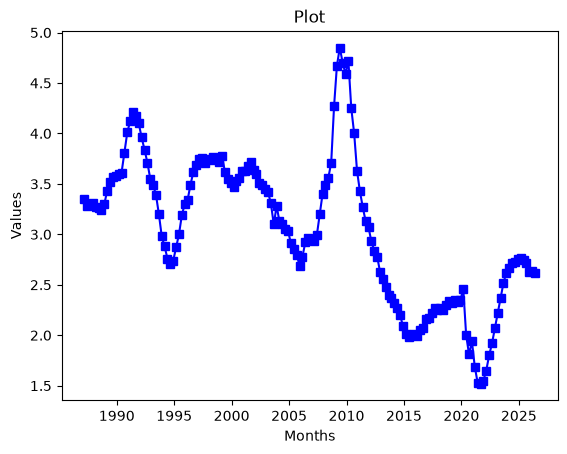

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
#------------------------------

# - Convert columns into series  
#------------------------------
def plot_series_from_excel(file_path, sheet, row, column, header_name):

    # Example: Start reading from Excel Row 5 (index 4) and Column 'C'
    df = pd.read_excel(
        file_path, 
        sheet_name=sheet,   # Specify your sheet name
        skiprows=row,            # Skips the first 4 rows (starts reading at row 5)
        usecols=column,           # Only reads column C
        header=header_name            # Set to None if row 5 doesn't contain a header
    )

    # Convert the resulting single-column DataFrame into a Pandas Series
    excel_series = df.iloc[:, 0]

    return excel_series

DRCLACBS = plot_series_from_excel("datasets/targets_FRB_CHGDEL.xlsx" ,"FRB_CHGDEL_transposed", 10, "F", None)
DROCLACBS = plot_series_from_excel("datasets/targets_FRB_CHGDEL.xlsx" ,"FRB_CHGDEL_transposed", 26, "J", None)
CORCACBS = plot_series_from_excel("datasets/targets_FRB_CHGDEL.xlsx" ,"FRB_CHGDEL_transposed", 2, "AB", None)
COROCLACBS = plot_series_from_excel("datasets/targets_FRB_CHGDEL.xlsx" ,"FRB_CHGDEL_transposed", 2, "AF", None)


Quarters = plot_series_from_excel("datasets/targets_FRB_CHGDEL.xlsx" ,"FRB_CHGDEL_transposed", 10, "A", None)


# -  Plot 2-D x and y series made above
plt.xlabel('Months')
plt.ylabel('Values')
plt.title('Plot')


plt.plot(Quarters, DRCLACBS, label='Trend A', color='blue', marker='s')

#### Stationarity

Links: </br> https://machinelearningmastery.com/time-series-data-stationary-python/

##### 1. Applying Tcodes

In [28]:
import pandas as pd
import numpy as np

qd_raw = pd.read_csv("datasets/2026-02-QD.csv")   # raw download (has 'factors' + 'transform' rows)

# pull out the tcode row, then keep only the real data rows
tcodes = qd_raw[qd_raw["sasdate"] == "transform"].iloc[0, 1:].astype(int)
qd = qd_raw[~qd_raw["sasdate"].isin(["factors", "transform"])].dropna(subset=["sasdate"]).copy()

qd.index = pd.to_datetime(qd.pop("sasdate")).dt.to_period("Q")   # 3/1/1985 -> 1985Q1
qd.index.name = "quarter"
qd = qd.astype(float)

def apply_tcode(x, t):
    if t == 1: return x                              # level
    if t == 2: return x.diff()                       # first difference
    if t == 3: return x.diff().diff()                # second difference
    if t == 4: return np.log(x)                      # log
    if t == 5: return np.log(x).diff()               # log difference (growth)
    if t == 6: return np.log(x).diff().diff()        # second log difference
    if t == 7: return x.pct_change().diff()          # change in % change

qd_stationary = pd.DataFrame({col: apply_tcode(qd[col], tcodes[col]) for col in qd.columns})
qd_stationary.head()

,GDPC1,PCECC96,PCDGx,PCESVx,PCNDx,GPDIC1,FPIx,Y033RC1Q027SBEAx,PNFIx,PRFIx,...,TNWMVBSNNCBBDIx,TLBSNNBx,TLBSNNBBDIx,TABSNNBx,TNWBSNNBx,TNWBSNNBBDIx,CNCFx,S&P 500,S&P div yield,S&P PE ratio
quarter,,,,,,,,,,,,,,,,,,,,,
1959Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,266663789.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1959Q2,0.022284,0.015326,0.036947,0.014833,0.008241,0.074909,0.030472,0.029499,0.028365,0.034310,...,-47518.32,0.037159,273337876.4,0.003550,-0.001910,-23856.03,0.012439,0.035218,-0.0753,0.035286
1959Q3,0.000697,0.010393,0.019149,0.013498,0.003807,-0.066760,0.010525,0.032060,0.026577,-0.018856,...,26569.25,0.025570,275143642.3,-0.000155,-0.004486,-38291.64,0.018986,0.021049,-0.0292,-0.017546
1959Q4,0.002846,0.001126,-0.048953,0.012061,0.006135,0.032025,-0.011664,-0.002028,-0.002811,-0.028690,...,-155074.21,-0.015357,254971696.3,-0.002280,-0.000072,-95194.28,0.060783,-0.016597,0.0852,-0.061597
1960Q1,0.022237,0.009521,0.031655,0.008993,0.002522,0.095789,0.032832,0.034184,0.034161,0.030303,...,161971.32,0.037677,278692553.5,0.009152,0.004281,86679.27,-0.051279,-0.026073,0.2278,-0.057371


##### 2. Appending Delinquency Data & Removing Prior 1985 Data

In [ ]:
targets = pd.read_excel(
    "datasets/targets_FRB_CHGDEL.xlsx",
    sheet_name="FRB_CHGDEL_transposed",
    header=None,
    skiprows=2,                  # data starts at Excel row 3 (1985Q1)
    usecols="A,F,J,AB,AF",       # date column + the 4 series
)
targets.columns = ["quarter", "DRCLACBS", "DROCLACBS", "CORCACBS", "COROCLACBS"]

# '1985Q1' / '1985:Q1' -> quarterly period so it lines up with QD's index
targets["quarter"] = pd.PeriodIndex(targets["quarter"].astype(str).str.replace(":", ""), freq="Q")
# if column A holds real Excel dates instead, use:
# targets["quarter"] = pd.to_datetime(targets["quarter"]).dt.to_period("Q")

targets = targets.set_index("quarter").apply(pd.to_numeric, errors="coerce")   # 'ND' -> NaN

# 1) join on quarters (this is what makes the two sources line up)
df = qd_stationary.join(targets, how="left")

# 2) THEN convert the quarter index to real dates: 1985Q1 -> 1985-01-01
df.index = df.index.to_timestamp(how="end").normalize() 
df.index.name = "date"

,DRCLACBS,DROCLACBS,CORCACBS,COROCLACBS
date,,,,
1985-03-31,NaN,NaN,0.82,0.51
1985-06-30,NaN,NaN,0.97,0.57
1985-09-30,NaN,NaN,1.15,0.67
1985-12-31,NaN,NaN,1.28,0.73
1986-03-31,NaN,NaN,1.35,0.75


In [30]:
df = df.loc["1985":] 

##### 3. DF Shape and Rename Variables

In [31]:
df.shape

(164, 249)

In [41]:
# Rename QD + add-on columns to the short "new names" from the FRED Dictionary tab
dic = pd.read_excel("datasets/TARGET_Var_Names.xlsx", sheet_name="FRED Dictionary")
dic = dic[dic["dataset"].isin(["FRED-QD", "FRED add-on"])].dropna(subset=["original name", "new name"])

new_names = dict(zip(dic["original name"], dic["new name"]))   # e.g. 'UNRATE' -> 'unemp_rate'
old_names = {new: old for old, new in new_names.items()}       # reverse lookup: old_names['unemp_rate'] -> 'UNRATE'
new_names["S&P PE rati"] = "stk_sp_pe"                         # QD's truncated column name, if your file has it

missing = [c for c in df.columns if c not in new_names]
print("Columns without a new name (left unchanged):", missing)

df = df.rename(columns=new_names)
df.loc["1985":, ["dq_consumer", "dq_other_cons", "co_consumer", "co_other_cons"]].head()

ValueError: Worksheet named 'FRED Dictionary' not found

In [32]:
df

,GDPC1,PCECC96,PCDGx,PCESVx,PCNDx,GPDIC1,FPIx,Y033RC1Q027SBEAx,PNFIx,PRFIx,...,TNWBSNNBx,TNWBSNNBBDIx,CNCFx,S&P 500,S&P div yield,S&P PE ratio,DRCLACBS,DROCLACBS,CORCACBS,COROCLACBS
date,,,,,,,,,,,,,,,,,,,,,
1985-03-31,0.009643,0.016847,0.034178,0.017965,0.006064,-0.027801,0.008994,-0.008904,0.011142,0.002269,...,-0.008834,6980.95,-0.020172,0.070686,-0.2301,0.033889,NaN,NaN,0.82,0.51
1985-06-30,0.008766,0.009139,0.011830,0.009158,0.007745,0.016889,0.012815,0.021593,0.014223,0.008320,...,-0.010920,-19838.44,0.021644,0.041431,-0.1228,0.021121,NaN,NaN,0.97,0.57
1985-09-30,0.015157,0.018817,0.062000,0.013383,0.008192,-0.006841,-0.004068,-0.013925,-0.011433,0.018370,...,0.000673,-11125.95,0.019411,0.018762,-0.0276,0.027141,NaN,NaN,1.15,0.67
1985-12-31,0.007407,0.002164,-0.035139,0.007990,0.008915,0.036194,0.018837,0.018500,0.017929,0.021494,...,0.020908,30725.60,-0.030009,0.045167,-0.1402,0.065171,NaN,NaN,1.28,0.73
1986-03-31,0.009294,0.008704,0.020082,0.004144,0.012640,-0.000293,0.002840,-0.010046,-0.009951,0.039723,...,0.010559,42353.04,-0.055629,0.110272,-0.3729,0.147688,NaN,NaN,1.35,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31,0.005939,0.010422,0.028339,0.008217,0.008190,-0.012292,0.000211,-0.007731,-0.001643,0.006667,...,0.005368,-29358.45,0.060085,0.063778,-0.0570,0.046801,2.76,2.44,2.97,1.18
2025-03-31,0.000358,0.001609,-0.013340,0.003462,0.003476,0.052849,0.018354,0.046267,0.025499,-0.006921,...,-0.011595,-11818.92,0.011306,-0.001747,0.0260,-0.028224,2.77,2.39,3.00,1.22
2025-06-30,0.009860,0.005205,0.009585,0.004587,0.004998,-0.031535,0.011938,0.017281,0.018329,-0.011113,...,-0.000665,-14619.04,0.028407,-0.028176,0.0601,-0.060893,2.75,2.38,2.87,1.20


#### Stationarity Test

##### 1. Setup ADF and KPSS

In [34]:
# A series is STATIONARY if its average and spread stay roughly the same over time
# (no long upward/downward trend). Regression models assume this; trending series
# can produce strong-looking but meaningless relationships.
#
# We use two tests that ask the question from opposite directions:
#   ADF  test: assumes NOT stationary.  p < 0.05  -> evidence it IS stationary
#   KPSS test: assumes IS stationary.   p < 0.05  -> evidence it is NOT stationary
# When both agree, we can trust the answer.

import warnings
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

ALPHA = 0.05   # significance level

##### 2. ADF and KPSS Functions

In [35]:
def test_stationarity(series):
    """Run ADF and KPSS on one series and return the p-values plus a verdict."""
    s = series.dropna()                      # tests can't handle missing values
    if len(s) < 20 or s.nunique() < 2:       # too short or constant -> can't test
        return {"obs": len(s), "adf_p": None, "kpss_p": None, "verdict": "Not enough data"}

    with warnings.catch_warnings():          # KPSS warns when p is outside its lookup table
        warnings.simplefilter("ignore")
        adf_p  = adfuller(s, autolag="AIC")[1]                  # [1] = p-value
        kpss_p = kpss(s, regression="c", nlags="auto")[1]

    adf_says_stationary  = adf_p  < ALPHA
    kpss_says_stationary = kpss_p >= ALPHA

    if adf_says_stationary and kpss_says_stationary:
        verdict = "Stationary"
    elif not adf_says_stationary and not kpss_says_stationary:
        verdict = "Non-stationary"
    else:
        verdict = "Unclear (tests disagree)"

    return {"obs": len(s), "adf_p": round(adf_p, 4), "kpss_p": round(kpss_p, 4), "verdict": verdict}

##### 3. Run on Every Variable

In [37]:
results = pd.DataFrame({col: test_stationarity(df[col]) for col in df.columns}).T
results.index.name = "variable"
results = results.sort_values("verdict")
#results
print(results.to_string())

                  obs   adf_p  kpss_p                   verdict
variable                                                       
UMCSENTx          164  0.2963  0.0367            Non-stationary
REALLNx           164  0.2203  0.0154            Non-stationary
HWIx              164   0.567    0.01            Non-stationary
TLBSHNOx          164  0.4082    0.01            Non-stationary
LIABPIx           164  0.1143  0.0111            Non-stationary
GS1TB3Mx          164  0.2033    0.01            Non-stationary
NWPIx             164  0.8468    0.01            Non-stationary
CES3000000008x    164   0.078  0.0259            Non-stationary
AHETPIx           164  0.0619  0.0219            Non-stationary
TLBSNNBBDIx       164  0.2301    0.01            Non-stationary
OPHMFG            155   0.557    0.01            Non-stationary
CUMFNS            164  0.1365    0.01            Non-stationary
DROCLACBS         140  0.0528    0.01            Non-stationary
DRCLACBS          156  0.0765    0.01   

##### 4. Stationarity Summary

In [38]:
print("How many variables fall in each group:")
print(results["verdict"].value_counts(), "\n")

print("Non-stationary variables (consider differencing these):")
print(results[results["verdict"] == "Non-stationary"].index.tolist(), "\n")

target_cols = ["DRCLACBS", "DROCLACBS", "CORCACBS", "COROCLACBS"]
print("Delinquency / charge-off targets:")
results.loc[target_cols]

How many variables fall in each group:
verdict
Stationary                  212
Unclear (tests disagree)     23
Non-stationary               14
Name: count, dtype: int64 

Non-stationary variables (consider differencing these):
['UMCSENTx', 'REALLNx', 'HWIx', 'TLBSHNOx', 'LIABPIx', 'GS1TB3Mx', 'NWPIx', 'CES3000000008x', 'AHETPIx', 'TLBSNNBBDIx', 'OPHMFG', 'CUMFNS', 'DROCLACBS', 'DRCLACBS'] 

Delinquency / charge-off targets:


,obs,adf_p,kpss_p,verdict
variable,,,,
DRCLACBS,156,0.0765,0.01,Non-stationary
DROCLACBS,140,0.0528,0.01,Non-stationary
CORCACBS,164,0.003,0.1,Stationary
COROCLACBS,164,0.0336,0.1,Stationary


##### 5. Difference and Retest 

In [39]:
# Take the first difference (change from last quarter) of each non-stationary
# or unclear series and test again. If it becomes stationary, use the differenced version.
to_fix = results[results["verdict"] != "Stationary"].index

retest = pd.DataFrame({col: test_stationarity(df[col].diff()) for col in to_fix}).T
retest.index.name = "variable (differenced)"
retest

,obs,adf_p,kpss_p,verdict
variable (differenced),,,,
UMCSENTx,163,0.0,0.1,Stationary
REALLNx,163,0.0,0.1,Stationary
HWIx,163,0.0,0.1,Stationary
TLBSHNOx,163,0.0064,0.1,Stationary
LIABPIx,163,0.0,0.1,Stationary
GS1TB3Mx,163,0.0,0.1,Stationary
NWPIx,163,0.0,0.1,Stationary
CES3000000008x,163,0.0,0.1,Stationary
AHETPIx,163,0.0,0.1,Stationary


#### Stationarity Plots

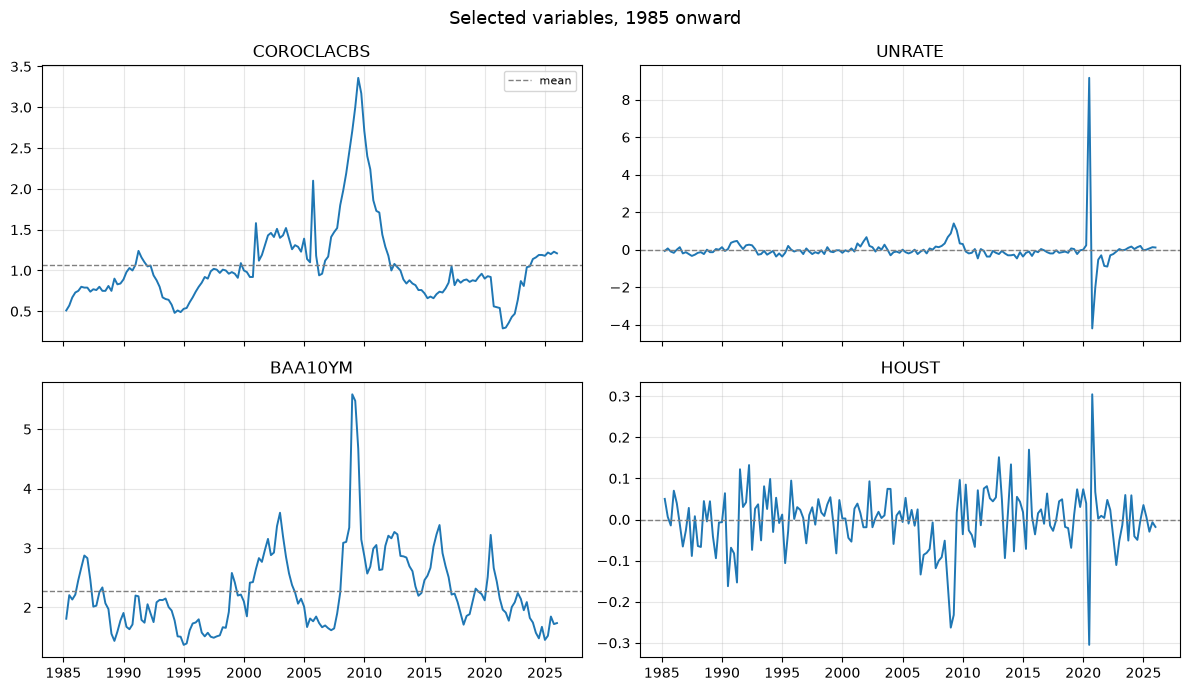

In [40]:
import matplotlib.pyplot as plt

VARS_TO_PLOT = ["COROCLACBS", "UNRATE", "BAA10YM", "HOUST"]   # <- change these 4 names

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

for ax, var in zip(axes.flat, VARS_TO_PLOT):
    s = df[var].dropna()
    ax.plot(s.index, s, linewidth=1.4)
    ax.axhline(s.mean(), color="grey", linestyle="--", linewidth=1, label="mean")
    ax.set_title(var)
    ax.grid(alpha=0.3)

axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle("Selected variables, 1985 onward", fontsize=13)
fig.tight_layout()
plt.show()

### Other

Targets: 1985Q1 to 2026Q2
DRCLACBS      1987Q1
DROCLACBS     1991Q1
CORCACBS      1985Q1
COROCLACBS    1985Q1
Name: first value, dtype: period[Q-DEC]
QD: (268, 245) | tcodes found: False


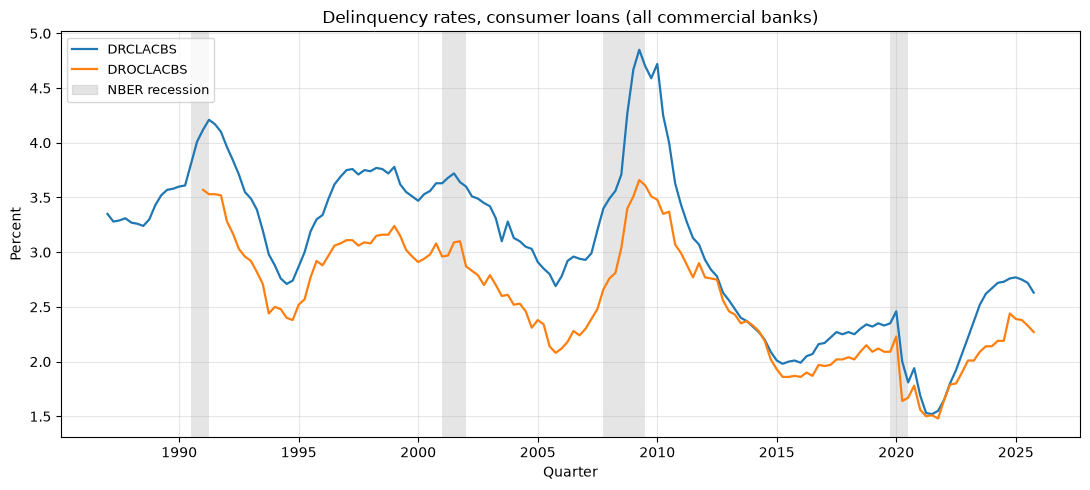

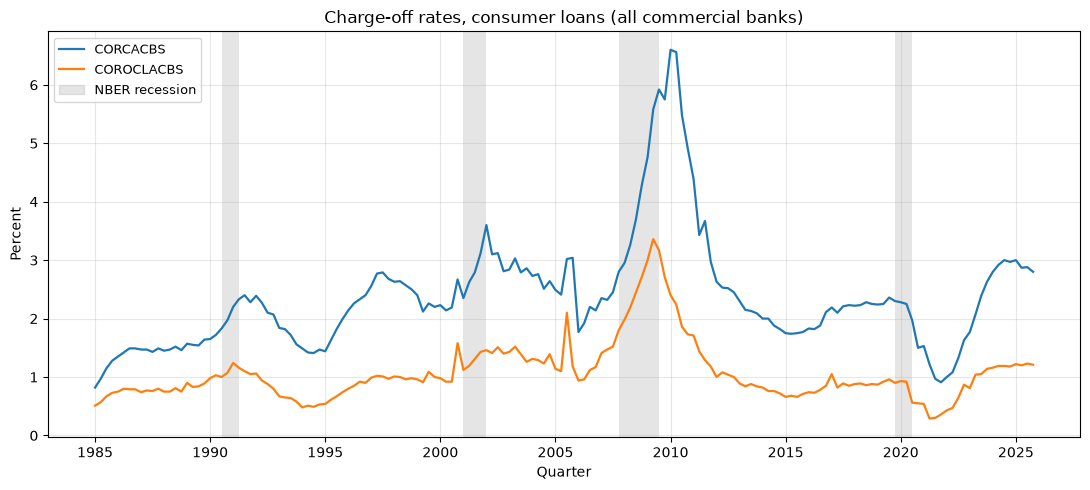

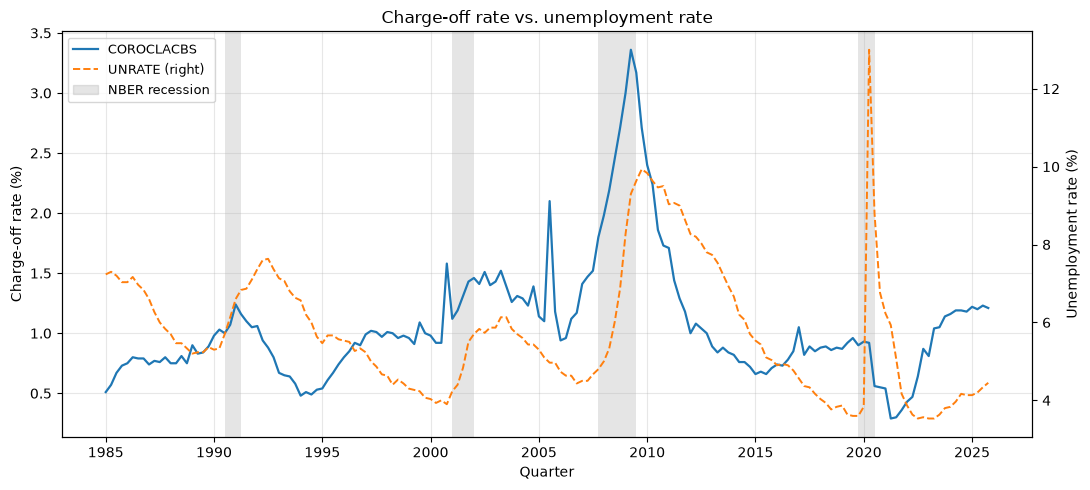

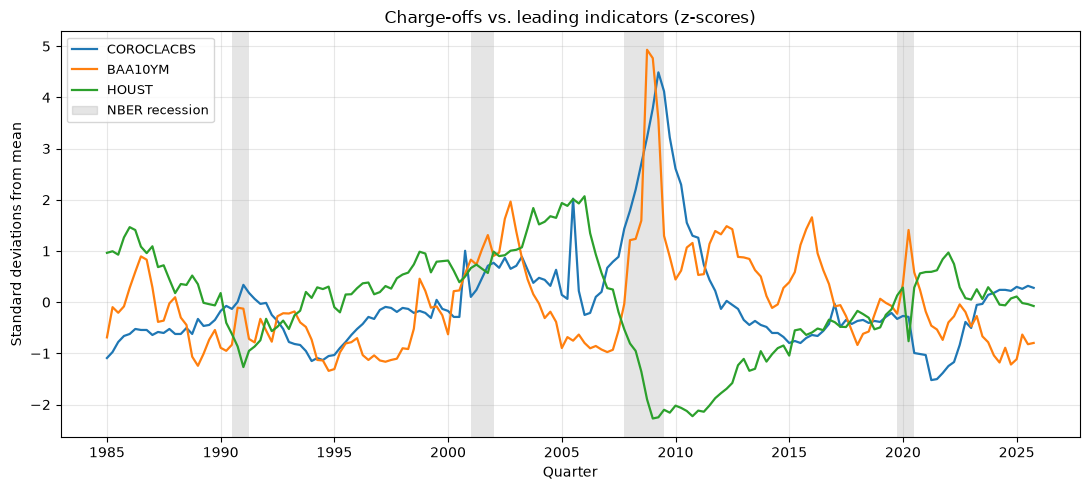

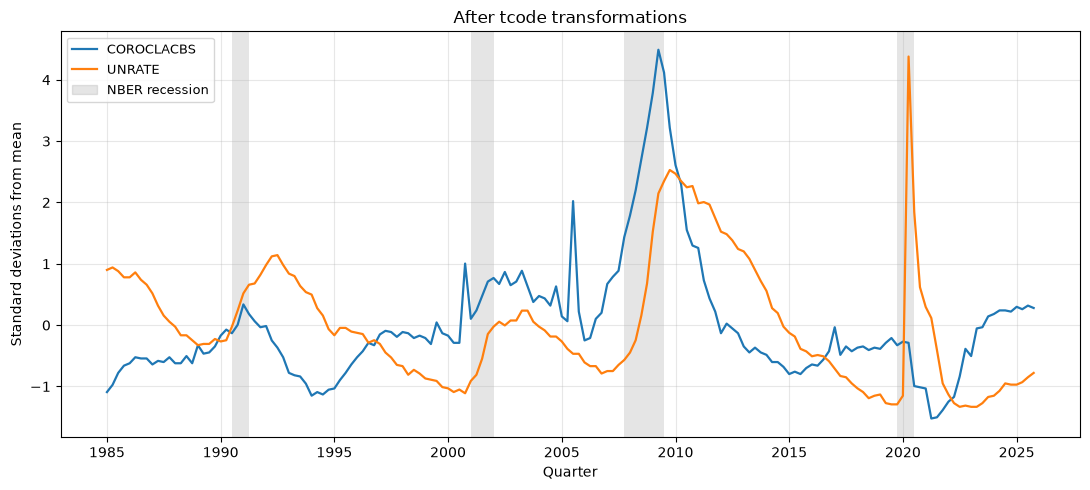

In [33]:
"""
Load FRED-QD (CSV) and Fed charge-off / delinquency (Excel) series onto ONE
quarterly index, optionally make them stationary with tcodes, and plot them.

Sections
  1. Settings          <- the only part you normally edit
  2. Date helper       -> turns any date format into a quarter (e.g. 1985Q1)
  3. Loaders           -> load_excel_series(), load_fred_csv()
  4. Transformations   -> apply_tcode(), transform_frame()
  5. Plotting          -> plot_series()
  6. Example usage
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# 1. SETTINGS - edit paths, sheet name and column letters here
# =============================================================================
TARGETS_XLSX  = "datasets/targets_FRB_CHGDEL.xlsx"
TARGETS_SHEET = "FRB_CHGDEL_transposed"
DATE_COLUMN   = "A"          # column holding the quarter labels
FIRST_DATA_ROW = 3           # Excel row number of the FIRST data row (1985Q1)

# name you want in Python  ->  Excel column letter
TARGET_COLUMNS = {
    "DRCLACBS":   "F",       # delinquency rate, all consumer loans   (starts 1987Q1)
    "DROCLACBS":  "J",       # delinquency rate, other consumer loans (starts 1991Q1)
    "CORCACBS":   "AB",      # charge-off rate, all consumer loans    (starts 1985Q1)
    "COROCLACBS": "AF",      # charge-off rate, other consumer loans  (starts 1985Q1)
}

QD_CSV = "datasets/2026-02-QD_edited.csv"   # raw download keeps the tcode row; *_edited.csv also works


# =============================================================================
# 2. DATE HELPER
# =============================================================================
def to_quarter(values):
    """
    Convert dates in any common format to a quarterly PeriodIndex.
    Handles '1985Q1', '1985:Q1', Excel dates, and '3/1/1985' (FRED-QD style).

    Why: FRED-QD labels a quarter by its LAST month (3/1, 6/1, ...) while FRED
    and the Fed label it by its FIRST month (1/1, 4/1, ...). Converting both to
    periods like 1985Q1 makes them line up when joined.
    """
    s = pd.Series(values).astype(str).str.strip().str.replace(":", "", regex=False)
    looks_like_quarter = s.str.match(r"^\d{4}\s*Q[1-4]$", case=False)
    if looks_like_quarter.all():
        return pd.PeriodIndex(s.str.replace(" ", "").str.upper(), freq="Q")
    return pd.PeriodIndex(pd.to_datetime(values), freq="Q")


# =============================================================================
# 3. LOADERS
# =============================================================================
def load_excel_series(file_path, sheet, columns, date_column="A", first_data_row=2):
    """
    Read several columns from one Excel sheet into a DataFrame indexed by quarter.

    columns        : dict {python_name: excel_column_letter}
    first_data_row : Excel row number (1-based) where data begins

    Every series shares the date column, so series that start later
    (e.g. DROCLACBS in 1991) are simply NaN before their first value. There's
    no need to give each series its own skiprows offset, and they can't
    drift out of alignment with the dates.
    """
    letters = [date_column] + list(columns.values())
    raw = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None,                      # we name the columns ourselves
        skiprows=first_data_row - 1,      # Excel row N -> skip N-1 rows
        usecols=",".join(letters),
    )
    # pandas returns usecols in sheet order, so map each letter to its position
    order = sorted(letters, key=_col_to_num)
    raw.columns = [("date" if L == date_column else _name_for(L, columns)) for L in order]

    raw = raw.dropna(subset=["date"])
    raw.index = to_quarter(raw.pop("date"))
    raw.index.name = "quarter"

    # Fed files use text like 'ND' (no data) -> turn anything non-numeric into NaN
    return raw.apply(pd.to_numeric, errors="coerce")[list(columns)]


def load_fred_csv(file_path, freq="Q"):
    """
    Load a FRED-QD (or FRED-MD with freq='M') CSV.

    Returns
      data   : DataFrame indexed by quarter (or month), numeric values
      tcodes : Series {column: tcode}, or None if the file has no transform row
               (e.g. an edited copy where those rows were removed)
    """
    raw = pd.read_csv(file_path)
    first_col = raw.columns[0]                      # 'sasdate'
    labels = raw[first_col].astype(str).str.strip().str.lower()

    # FRED-QD: row 'factors' then row 'transform'; FRED-MD: row 'Transform:'
    tcode_rows = labels.str.startswith("transform")
    meta_rows = tcode_rows | labels.str.startswith("factors")

    tcodes = None
    if tcode_rows.any():
        tcodes = raw.loc[tcode_rows].iloc[0, 1:].astype(float).astype(int)

    data = raw.loc[~meta_rows].dropna(subset=[first_col]).copy()
    dates = pd.to_datetime(data.pop(first_col))
    data.index = (pd.PeriodIndex(dates, freq="Q") if freq == "Q"
                  else pd.PeriodIndex(dates, freq="M"))
    data.index.name = "quarter" if freq == "Q" else "month"
    return data.apply(pd.to_numeric, errors="coerce"), tcodes


def _col_to_num(letter):
    """Excel letter -> number ('A'->1, 'AB'->28) so columns can be sorted."""
    n = 0
    for ch in letter.upper():
        n = n * 26 + (ord(ch) - 64)
    return n


def _name_for(letter, columns):
    return next(name for name, L in columns.items() if L.upper() == letter.upper())


# =============================================================================
# 4. TRANSFORMATIONS (stationarity)
# =============================================================================
TCODE_MEANING = {
    1: "level (no change)",
    2: "first difference",
    3: "second difference",
    4: "log",
    5: "log difference (~growth rate)",
    6: "second log difference",
    7: "change in percent change",
}


def apply_tcode(series, tcode):
    """Apply one McCracken & Ng transformation code to a Series."""
    x = series.astype(float)
    if tcode in (4, 5, 6):
        x = np.log(x.where(x > 0))               # log of non-positive -> NaN, not an error
    if tcode == 1 or tcode == 4:
        return x
    if tcode == 2 or tcode == 5:
        return x.diff()
    if tcode == 3 or tcode == 6:
        return x.diff().diff()
    if tcode == 7:
        return x.pct_change(fill_method=None).diff()
    raise ValueError(f"Unknown tcode {tcode}")


def transform_frame(df, tcodes, default=1):
    """
    Apply tcodes to every column. Columns without a tcode (e.g. the add-ons)
    use `default` - 1 = keep as level, 2 = first difference.
    """
    out = {}
    for col in df.columns:
        code = int(tcodes.get(col, default)) if tcodes is not None else default
        out[col] = apply_tcode(df[col], code)
    return pd.DataFrame(out, index=df.index)


# =============================================================================
# 5. PLOTTING
# =============================================================================
# NBER recessions (peak quarter -> trough quarter); shaded grey on plots
NBER_RECESSIONS = [
    ("1960Q2", "1961Q1"), ("1969Q4", "1970Q4"), ("1973Q4", "1975Q1"),
    ("1980Q1", "1980Q3"), ("1981Q3", "1982Q4"), ("1990Q3", "1991Q1"),
    ("2001Q1", "2001Q4"), ("2007Q4", "2009Q2"), ("2019Q4", "2020Q2"),
]


def plot_series(df, columns, right_axis=None, start=None, end=None,
                standardize=False, recessions=True,
                title="", ylabel="Percent", right_ylabel=""):
    """
    Plot one or more quarterly series against time.

    columns      : list of column names for the left axis
    right_axis   : list of column names for a second y-axis (different units/scale)
    start / end  : e.g. '1985Q1', '2025Q4' to zoom in
    standardize  : True -> z-scores, so series on very different scales can be
                   compared by SHAPE (good for spotting leads/lags in EDA)
    recessions   : shade NBER recessions
    """
    right_axis = right_axis or []
    data = df[columns + right_axis].loc[start:end]
    if standardize:
        data = (data - data.mean()) / data.std()
        ylabel = "Standard deviations from mean"

    x = data.index.to_timestamp()                  # periods -> dates matplotlib understands
    fig, ax = plt.subplots(figsize=(11, 5))
    colors = iter(plt.rcParams["axes.prop_cycle"].by_key()["color"] * 3)  # one color per series

    for col in columns:
        ax.plot(x, data[col], label=col, linewidth=1.6, color=next(colors))

    ax2 = None
    if right_axis and not standardize:
        ax2 = ax.twinx()
        for col in right_axis:
            ax2.plot(x, data[col], label=f"{col} (right)", linestyle="--",
                     linewidth=1.4, color=next(colors))
        ax2.set_ylabel(right_ylabel)
    elif right_axis:                                # standardized -> same axis is fine
        for col in right_axis:
            ax.plot(x, data[col], label=col, linestyle="--", linewidth=1.4, color=next(colors))

    if recessions:
        lo, hi = x.min(), x.max()
        for peak, trough in NBER_RECESSIONS:
            p = pd.Period(peak, "Q").to_timestamp()
            t = pd.Period(trough, "Q").to_timestamp(how="end")
            if t >= lo and p <= hi:
                ax.axvspan(max(p, lo), min(t, hi), color="grey", alpha=0.2, linewidth=0)

    ax.set_title(title)
    ax.set_xlabel("Quarter")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

    handles, labels = ax.get_legend_handles_labels()
    if ax2 is not None:
        h2, l2 = ax2.get_legend_handles_labels()
        handles, labels = handles + h2, labels + l2
    if recessions:
        handles.append(plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.2))
        labels.append("NBER recession")
    ax.legend(handles, labels, loc="upper left", fontsize=9)

    fig.tight_layout()
    plt.show()
    return fig


# =============================================================================
# 6. EXAMPLE USAGE
# =============================================================================
if __name__ == "__main__":
    # --- load ---------------------------------------------------------------
    targets = load_excel_series(TARGETS_XLSX, TARGETS_SHEET, TARGET_COLUMNS,
                                date_column=DATE_COLUMN, first_data_row=FIRST_DATA_ROW)
    qd, qd_tcodes = load_fred_csv(QD_CSV)

    print("Targets:", targets.index.min(), "to", targets.index.max())
    print(targets.apply(lambda s: s.first_valid_index()).rename("first value"))
    print("QD:", qd.shape, "| tcodes found:", qd_tcodes is not None)

    # --- combine on the shared quarterly index ------------------------------
    combined = qd.join(targets, how="left")         # keeps QD's full history; targets NaN pre-1985

    # --- plot raw levels ----------------------------------------------------
    plot_series(combined, ["DRCLACBS", "DROCLACBS"], start="1985Q1",
                title="Delinquency rates, consumer loans (all commercial banks)")

    plot_series(combined, ["CORCACBS", "COROCLACBS"], start="1985Q1",
                title="Charge-off rates, consumer loans (all commercial banks)")

    # target vs. a macro driver on two axes
    plot_series(combined, ["COROCLACBS"], right_axis=["UNRATE"], start="1985Q1",
                title="Charge-off rate vs. unemployment rate",
                ylabel="Charge-off rate (%)", right_ylabel="Unemployment rate (%)")

    # shapes compared on one scale (leading indicators should turn first)
    plot_series(combined, ["COROCLACBS", "BAA10YM", "HOUST"], start="1985Q1",
                standardize=True, title="Charge-offs vs. leading indicators (z-scores)")

    # --- stationary version for modeling -----------------------------------
    stationary = transform_frame(combined, qd_tcodes, default=1)  # add-ons kept as levels
    plot_series(stationary, ["COROCLACBS", "UNRATE"], start="1985Q1",
                standardize=True, title="After tcode transformations")